# Задание 4.11
## Встреча $n$ лиц с одинаковым временем ожидания

### Условие:
$n$ лиц условились о встрече между 10 и 11 часами, причём договорились ждать друг друга не более $60q$ минут ($q<1$). Моменты прихода выбираются «наудачу». Докажите, что вероятность встречи $P_n=nq^{n-1}-(n-1)q^n$. Проверьте формулу для $n=2$ и $n=3$. Для $n=3$ найдите также вероятность того, что встреча по крайней мере двух лиц состоится.

### Модель:
Измеряем время в долях часа: моменты прихода $t_1,\dots,t_n$ независимы и равномерны на $[0,1]$, $\Omega=[0,1]^n$. Каждый присутствует в течение $[t_i,\,t_i+q]$. Встреча **всех $n$ лиц** состоится, если существует момент, когда присутствуют все. Раньше всех уходит самый ранний (он уходит в $t_{\min}+q$), поэтому достаточно, чтобы последний пришедший (в момент $t_{\max}$) застал самого раннего:
$$\text{встреча}\iff t_{\max}-t_{\min}\le q .$$
(Каждый ждёт $q$, поэтому критическим является ожидание самого раннего.)

### Доказательство формулы $P_n$:
Пусть $x$ — момент прихода самого раннего из $n$ лиц (его номер можно выбрать $n$ способами). Остальные $n-1$ человек должны прийти позже $x$ и не позже $x+q$, то есть в отрезок $[x,\ \min(x+q,1)]$ длины $\min(q,\,1-x)$. Вероятность этого равна $\min(q,1-x)^{n-1}$. Поэтому
$$P_n=n\int_0^1\min(q,1-x)^{n-1}dx=n\Bigl[\int_0^{1-q}q^{n-1}dx+\int_{1-q}^1(1-x)^{n-1}dx\Bigr]=n\Bigl[(1-q)q^{n-1}+\frac{q^n}n\Bigr]=nq^{n-1}-(n-1)q^n .$$
(Это функция распределения размаха $t_{\max}-t_{\min}$ выборки из равномерного распределения.)

### Проверка для $n=2$ и $n=3$:
- $n=2$: $P_2=2q-q^2=1-(1-q)^2$. Геометрически: в квадрате $[0,1]^2$ встреча $\Leftrightarrow|t_1-t_2|\le q$; дополнение — два треугольника с катетами $1-q$, площадь $2\cdot\frac{(1-q)^2}2$ ✓.
- $n=3$: $P_3=3q^2-2q^3$ (в единичном кубе область $\max-\min\le q$ — «призма» вдоль диагонали).

### Встреча по крайней мере двух лиц ($n=3$):
Хотя бы пара $i,j$ встречается $\iff$ $|t_i-t_j|\le q$ для некоторой пары. Упорядочим моменты $t_{(1)}<t_{(2)}<t_{(3)}$; ближайшими являются соседние, поэтому «ни одна пара не встретилась» $\iff$ оба промежутка $g_1=t_{(2)}-t_{(1)}>q$ и $g_2=t_{(3)}-t_{(2)}>q$. Тогда (подстановка $s_1=t_{(1)},\ s_2=t_{(2)}-q,\ s_3=t_{(3)}-2q$, $0\le s_1\le s_2\le s_3\le1-2q$):
$$\mathbb P(\text{никто не встретился})=3!\cdot\frac{(1-2q)^3}{3!}=(1-2q)^3\quad(q<\tfrac12),$$
$$\boxed{\ \mathbb P(\text{хотя бы двое встретились})=1-(1-2q)^3\ \ (q\le\tfrac12);\qquad=1\ \ (q\ge\tfrac12)\ }$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка формул моделированием: $P_n(q)$ для $n=2,\dots,6$ и $q=0{,}25$ (15 минут)

In [2]:
def P_formula(n, q): return n*q**(n - 1) - (n - 1)*q**n
def P_two_of_three(q): return 1 - max(0.0, 1 - 2*q)**3

def meeting_all(n, q, N):
    t = rng.random((N, n))
    return (t.max(axis=1) - t.min(axis=1)) <= q              # встреча всех: размах моментов прихода ≤ q

q, N = 0.25, 300_000
print(' n   формула nq^(n−1) − (n−1)q^n    оценка p̂ (N = 300 000)')
for n in range(2, 7):
    print(f'{n:2d}        {P_formula(n, q):.6f}                    {meeting_all(n, q, N).mean():.6f}')

t3 = rng.random((N, 3)); ts = np.sort(t3, axis=1)
hit2 = (np.minimum(ts[:, 1] - ts[:, 0], ts[:, 2] - ts[:, 1]) <= q)       # хотя бы одна пара встретилась
print(f'\nn = 3, хотя бы двое: формула 1 − (1−2q)^3 = {P_two_of_three(q):.6f};  оценка {hit2.mean():.6f}')
hit_n2, hit_n3 = meeting_all(2, q, N), (ts[:, 2] - ts[:, 0]) <= q
print('проверка n=2: 2q − q² =', 2*q - q*q, ';  n=3: 3q² − 2q³ =', 3*q*q - 2*q**3)

 n   формула nq^(n−1) − (n−1)q^n    оценка p̂ (N = 300 000)
 2        0.437500                    0.438917
 3        0.156250                    0.156737
 4        0.050781                    0.051170
 5        0.015625                    0.015723
 6        0.004639                    0.004730

n = 3, хотя бы двое: формула 1 − (1−2q)^3 = 0.875000;  оценка 0.874320
проверка n=2: 2q − q² = 0.4375 ;  n=3: 3q² − 2q³ = 0.15625


### Графики: статистическая устойчивость ($q=0{,}25$) и зависимость $P_n$ от $q$

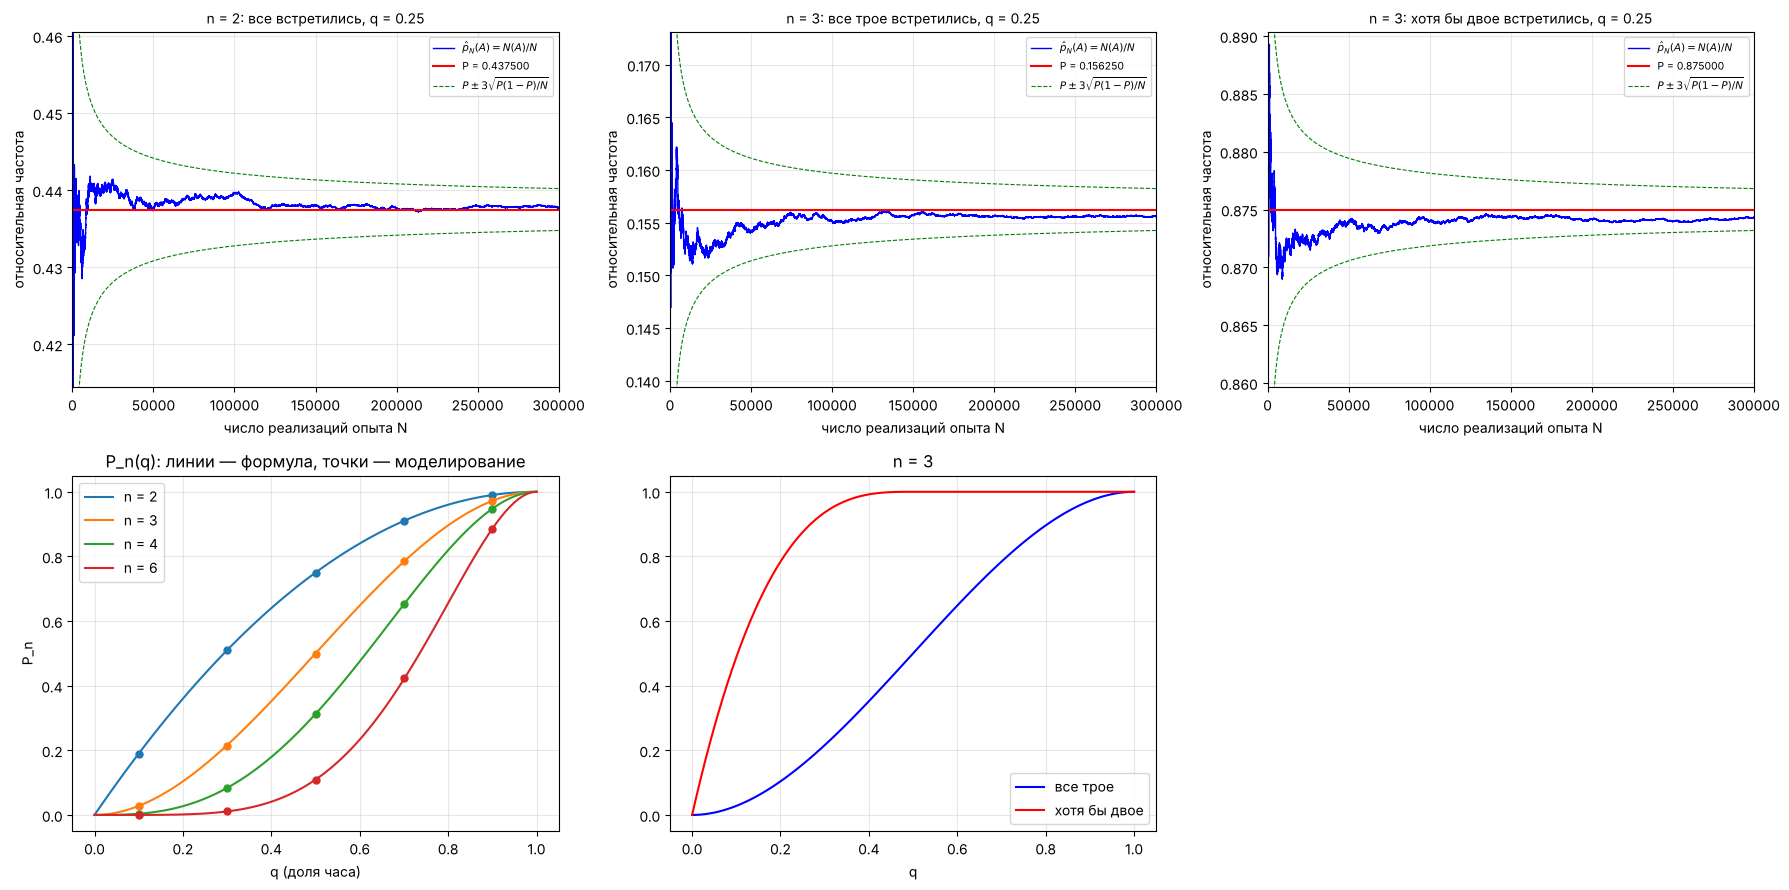

In [3]:
fig, axs = plt.subplots(2, 3, figsize=(18, 9))
plot_frequency(axs[0, 0], hit_n2, P_formula(2, q), f'n = 2: все встретились, q = {q}')
plot_frequency(axs[0, 1], hit_n3, P_formula(3, q), f'n = 3: все трое встретились, q = {q}')
plot_frequency(axs[0, 2], hit2, P_two_of_three(q), f'n = 3: хотя бы двое встретились, q = {q}')
qs = np.linspace(0, 1, 101)
for n, col in zip([2, 3, 4, 6], ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']):
    axs[1, 0].plot(qs, P_formula(n, qs), color=col, label=f'n = {n}')
    qq = np.array([0.1, 0.3, 0.5, 0.7, 0.9]); axs[1, 0].plot(qq, [meeting_all(n, x_, 60_000).mean() for x_ in qq], 'o', color=col, ms=5)
axs[1, 0].set_xlabel('q (доля часа)'); axs[1, 0].set_ylabel('P_n'); axs[1, 0].grid(alpha=0.3); axs[1, 0].legend(); axs[1, 0].set_title('P_n(q): линии — формула, точки — моделирование')
axs[1, 1].plot(qs, [P_formula(3, x_) for x_ in qs], 'b-', label='все трое'); axs[1, 1].plot(qs, [P_two_of_three(x_) for x_ in qs], 'r-', label='хотя бы двое')
axs[1, 1].set_xlabel('q'); axs[1, 1].grid(alpha=0.3); axs[1, 1].legend(); axs[1, 1].set_title('n = 3')
axs[1, 2].axis('off')
plt.tight_layout(); plt.savefig('task_4_11.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
$P_n=nq^{n-1}-(n-1)q^n$ доказана (через распределение размаха моментов прихода); $P_2=2q-q^2$, $P_3=3q^2-2q^3$. Вероятность того, что для $n=3$ встретятся хотя бы двое: $1-(1-2q)^3$ при $q\le\frac12$ и $1$ при $q\ge\frac12$ (для $q=\frac14$: $\frac78=0{,}875$).